In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'c:\Users\HP\Downloads\Zomato-data-.csv')
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   name                         148 non-null    object
 1   online_order                 148 non-null    object
 2   book_table                   148 non-null    object
 3   rate                         148 non-null    object
 4   votes                        148 non-null    int64 
 5   approx_cost(for two people)  148 non-null    int64 
 6   listed_in(type)              148 non-null    object
dtypes: int64(2), object(5)
memory usage: 8.2+ KB
None


In [3]:
# I have columns of restaurant names with online/offline order ratings and vote 
# I can deduce the most liked restaurant the type of service and their ratings
#  I can deduce if people prefer online to offline
#  I can deduce couples favorite type of restaurant and the average cost.

In [4]:
print(df.columns)
print()
print(df.head(5))
print()
print(df.describe(include='all'))

Index(['name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost(for two people)', 'listed_in(type)'],
      dtype='object')

                    name online_order book_table   rate  votes  \
0                  Jalsa          Yes        Yes  4.1/5    775   
1         Spice Elephant          Yes         No  4.1/5    787   
2        San Churro Cafe          Yes         No  3.8/5    918   
3  Addhuri Udupi Bhojana           No         No  3.7/5     88   
4          Grand Village           No         No  3.8/5    166   

   approx_cost(for two people) listed_in(type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  

                   name online_order book_table   rate        votes  \
count               148          148        148    148   148.000000   
unique              145

In [8]:
print(df.isnull().sum())
print(df.duplicated().any())
print(df.duplicated().sum())

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64
False
0


In [9]:
df['rate'] = df['rate'].astype(str).str.split('/').str[0].astype(float)
print(df.head(5))

                    name online_order book_table  rate  votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   approx_cost(for two people) listed_in(type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


In [13]:
print(df['rate'].describe())
print()

ctg = df.select_dtypes(include='object').columns
print('categorical: ', ctg)
print()

nm = df.select_dtypes(include=['int64', 'float64']).columns
print('numerical: ', nm)

count    148.000000
mean       3.633108
std        0.402271
min        2.600000
25%        3.300000
50%        3.700000
75%        3.900000
max        4.600000
Name: rate, dtype: float64

categorical:  Index(['name', 'online_order', 'book_table', 'listed_in(type)'], dtype='object')

numerical:  Index(['rate', 'votes', 'approx_cost(for two people)'], dtype='object')


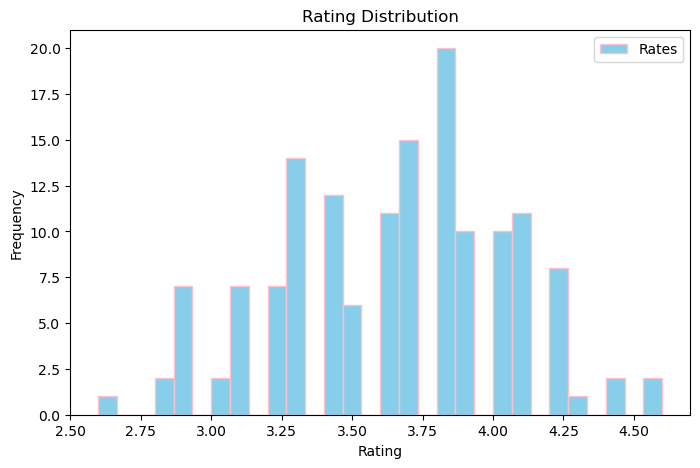

<Axes: xlabel='rate'>

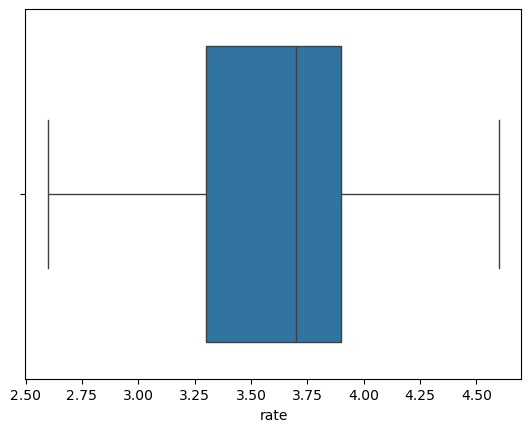

In [18]:
plt.figure(figsize=(8, 5))
plt.hist(df['rate'], bins=30, edgecolor='pink', color='skyblue', label='Rates')
plt.title('Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.legend()
plt.show()

plt.figure()

sns.boxplot(x=df['rate'])

In [21]:
print(df['listed_in(type)'].unique())
print(df['listed_in(type)'].value_counts())

['Buffet' 'Cafes' 'other' 'Dining']
listed_in(type)
Dining    110
Cafes      23
other       8
Buffet      7
Name: count, dtype: int64


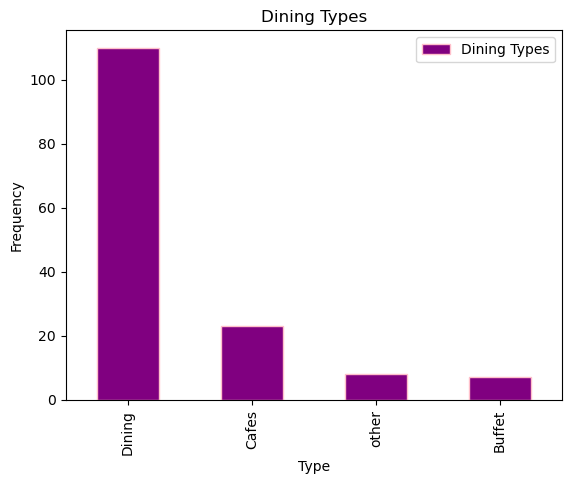

<Axes: xlabel='listed_in(type)', ylabel='count'>

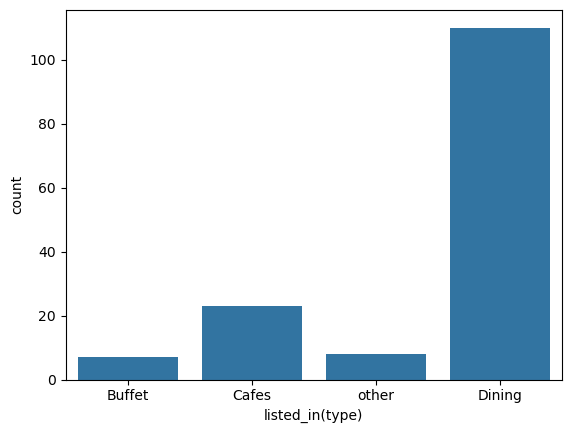

In [24]:
df['listed_in(type)'].value_counts().plot(kind='bar', color='purple', edgecolor='pink')
plt.title('Dining Types')
plt.xlabel('Type')
plt.ylabel('Frequency')
plt.legend(['Dining Types'])
plt.show()

plt.figure()

sns.countplot(x=df['listed_in(type)'])

In [35]:
most_voted = df.loc[df['votes'].idxmax(), ['name', 'votes', 'approx_cost(for two people)']]
print('Most Voted: ', most_voted)
print()

least_voted = df.loc[df['votes'].idxmin(), ['name', 'votes', 'approx_cost(for two people)']]
print('Least Voted: ', least_voted)
print()

top_voted = df.nlargest(3, 'votes')[['name', 'votes', 'approx_cost(for two people)']]
print('Top Voted: \n', top_voted)
print()

bottom_voted = df.nsmallest(3, 'votes')[['name', 'votes', 'approx_cost(for two people)']]
print('Bottom Voted: \n', bottom_voted)

Most Voted:  name                           Empire Restaurant
votes                                       4884
approx_cost(for two people)                  750
Name: 38, dtype: object

Least Voted:  name                           Spicy Tandoor
votes                                      0
approx_cost(for two people)              150
Name: 72, dtype: object

Top Voted: 
                  name  votes  approx_cost(for two people)
38  Empire Restaurant   4884                          750
86      Meghana Foods   4401                          600
7              Onesta   2556                          600

Bottom Voted: 
                      name  votes  approx_cost(for two people)
72          Spicy Tandoor      0                          150
75  Om Sri Vinayaka Chats      0                          500
84              Chill Out      0                          100


In [37]:
most_voted_per_type = (
    df.loc[df.groupby('listed_in(type)')['votes'].idxmax(), ['listed_in(type)', 'name', 'votes', 'approx_cost(for two people)']]
    .sort_values(by='votes', ascending=False)
)
print(most_voted_per_type)

   listed_in(type)               name  votes  approx_cost(for two people)
38           other  Empire Restaurant   4884                          750
86          Dining      Meghana Foods   4401                          600
7            Cafes             Onesta   2556                          600
2           Buffet    San Churro Cafe    918                          800


<Axes: xlabel='online_order', ylabel='rate'>

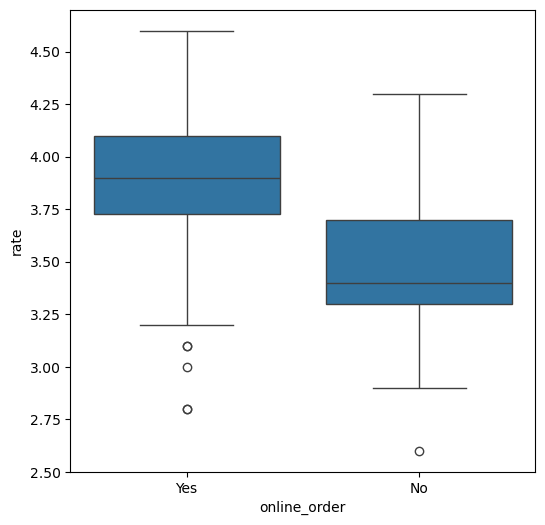

In [39]:
plt.figure(figsize = (6,6))
sns.boxplot(x = 'online_order', y = 'rate', data = df)